In [65]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
#sklearn preprocesin
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
#regressor model
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor, VotingRegressor, StackingRegressor
#metrices
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

import warnings
warnings.filterwarnings('ignore')

In [66]:
df=pd.read_csv('/content/sample_data/bangladesh_student_performance.csv')

In [67]:
df

,date,gender,age,address,famsize,Pstatus,M_Edu,F_Edu,M_Job,F_Job,relationship,smoker,tuition_fee,time_friends,ssc_result,hsc_result
0,29/04/2018,M,18,Rural,GT3,Together,3,2,At_home,Farmer,No,No,71672,4,4.22,3.72
1,29/04/2018,F,19,Rural,LE3,Apart,0,4,Other,Health,Yes,No,26085,5,3.47,2.62
2,29/04/2018,F,19,Rural,GT3,Together,0,3,Teacher,Services,No,No,40891,3,3.32,2.56
3,29/04/2018,F,19,Rural,LE3,Apart,2,3,At_home,Business,No,No,50600,2,4.57,4.17
4,29/04/2018,M,17,Rural,GT3,Together,1,1,At_home,Farmer,No,No,62458,2,4.50,3.94
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2013,29/04/2018,M,18,Urban,GT3,Together,2,2,Teacher,Health,No,No,108426,2,3.57,3.18
2014,29/04/2018,M,19,Urban,GT3,Together,0,3,Other,Teacher,Yes,No,100665,5,4.05,3.13
2015,29/04/2018,M,18,Urban,GT3,Together,3,2,Services,Farmer,Yes,No,92291,1,3.93,3.15
2016,29/04/2018,M,19,Rural,GT3,Together,0,2,At_home,Teacher,No,No,43926,3,3.34,2.83


In [68]:
# !pip install --force-reinstall "numpy<2.3.6" ydata-profiling

In [69]:
# from ydata_profiling import ProfileReport
# profile = ProfileReport( df , title="Bangladesh Student performance prediction", explorative = True  )
# profile.to_file("ydata.html")

In [70]:
len(df)

2018

In [71]:
len(df.columns)

16

In [72]:
df.columns

Index(['date', 'gender', 'age', 'address', 'famsize', 'Pstatus', 'M_Edu',
       'F_Edu', 'M_Job', 'F_Job', 'relationship', 'smoker', 'tuition_fee',
       'time_friends', 'ssc_result', 'hsc_result'],
      dtype='object')

In [73]:
#correlation for numeric columns
corr_target=df.select_dtypes(include=np.number).corr()['hsc_result'].sort_values(ascending=False)
print(corr_target)

hsc_result      1.000000
ssc_result      0.950178
M_Edu           0.063776
F_Edu           0.054811
tuition_fee     0.038068
age            -0.009857
time_friends   -0.156356
Name: hsc_result, dtype: float64


In [74]:
if 'date' in df.columns:
  df.drop( columns = ['date'], inplace=True )

Separate X and y

In [75]:
X=df.drop(columns='hsc_result',axis=1)
y=df['hsc_result']

Numerical Column and Categorical Columns

In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2018 entries, 0 to 2017
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   gender        2018 non-null   object 
 1   age           2018 non-null   int64  
 2   address       2018 non-null   object 
 3   famsize       2018 non-null   object 
 4   Pstatus       2018 non-null   object 
 5   M_Edu         2018 non-null   int64  
 6   F_Edu         2018 non-null   int64  
 7   M_Job         2018 non-null   object 
 8   F_Job         2018 non-null   object 
 9   relationship  2018 non-null   object 
 10  smoker        2018 non-null   object 
 11  tuition_fee   2018 non-null   int64  
 12  time_friends  2018 non-null   int64  
 13  ssc_result    2018 non-null   float64
 14  hsc_result    2018 non-null   float64
dtypes: float64(2), int64(5), object(8)
memory usage: 236.6+ KB


In [77]:
numeric_features=X.select_dtypes(include=['int64','float64']).columns
categorical_features=X.select_dtypes(include=['object']).columns

In [78]:
numeric_features

Index(['age', 'M_Edu', 'F_Edu', 'tuition_fee', 'time_friends', 'ssc_result'], dtype='object')

In [79]:
categorical_features

Index(['gender', 'address', 'famsize', 'Pstatus', 'M_Job', 'F_Job',
       'relationship', 'smoker'],
      dtype='object')

numeric feature scaling pipeline

In [80]:
num_transformer=Pipeline(
    steps=[
        ('imputer',SimpleImputer(strategy='median')),
        ('scaler',StandardScaler())


    ]
)

categorical features scaling pipeline

In [81]:
cat_transformer=Pipeline(
    steps=[
        ('imputer',SimpleImputer(strategy='most_frequent')),
        ('encoder',OneHotEncoder(handle_unknown='ignore'))
    ]
)

In [82]:
#combile
preprocessor=ColumnTransformer([
    ('num',num_transformer,numeric_features),
    ('cat',cat_transformer,categorical_features)
])

In [83]:
#train test
X_train,X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2 , random_state=42)

##Ensemble - boosting, stacking

In [84]:
reg_lr=LinearRegression()
reg_rf=RandomForestRegressor(n_estimators=100,random_state=42)
reg_gb=GradientBoostingRegressor(n_estimators=100,random_state=42)

In [85]:
#voting regressor
voting_reg= VotingRegressor(
    estimators=[
        ('lr',reg_lr),
        ('rf',reg_rf),
        ('gb',reg_gb)
    ]
)

In [86]:
#stating
stacking_reg=StackingRegressor(
    estimators=[
        ('rf',reg_rf),
        ('gb',reg_gb)
    ]
)

In [87]:
#directory for all model
model_to_train={
    'Linear Regression' : reg_lr,
    'Random Forest' : reg_rf,
    'Gradient Boosting': reg_gb,
    'Voting Ensemble ' : voting_reg,
    'Stacking Ensemble ' : stacking_reg
}

In [88]:
#training evaluation
results=[]
for name,model in model_to_train.items():
  pipe=Pipeline([
      ('preprocessor',preprocessor),
      ('model',model)
  ])

  pipe.fit(X_train,y_train)
  #prediction
  y_pred=pipe.predict(X_test)
  #evaluation
  r2 = r2_score(y_test,y_pred)
  rmse = np.sqrt(mean_squared_error(y_test,y_pred))
  mae = mean_absolute_error(y_test,y_pred)

  results.append({
      'model':name,
      "R2 Score" :r2,
      "RMSE": rmse,
      "MAE" : mae
  })

results_df=pd.DataFrame(results).sort_values('R2 Score',ascending=False)
print(results_df)

                model  R2 Score      RMSE       MAE
4  Stacking Ensemble   0.959873  0.122637  0.098391
2   Gradient Boosting  0.959565  0.123107  0.098902
3    Voting Ensemble   0.957528  0.126169  0.100838
1       Random Forest  0.950248  0.136556  0.108201
0   Linear Regression  0.945920  0.142371  0.111376


##Visualization

In [89]:
best_model_name=results_df.iloc[0]['model']
best_model_obj=model_to_train[best_model_name]
best_model_obj

StackingRegressor(estimators=[('rf', RandomForestRegressor(random_state=42)),
                              ('gb',
                               GradientBoostingRegressor(random_state=42))])

In [90]:
#final pipe
final_pipe=Pipeline([
    ('preprocessor',preprocessor),
    ('model',best_model_obj)
])

final_pipe.fit(X_train,y_train)
y_final_pred = final_pipe.predict(X_test)

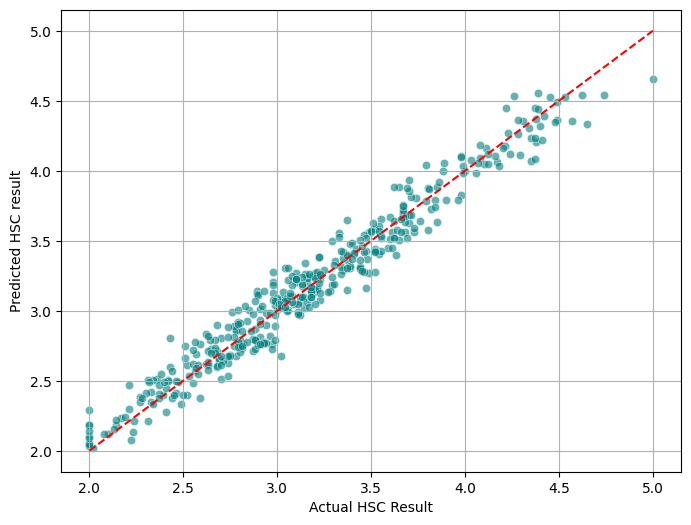

In [91]:
#plot
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_test, y=y_final_pred,alpha=0.6,color='teal')
plt.plot( [2,5] , [2,5], color = "red", linestyle = '--'  )
plt.xlabel("Actual HSC Result")
plt.ylabel("Predicted HSC result")

plt.grid(True)
plt.show()

#cross validation

In [92]:
from sklearn.model_selection  import cross_val_score

In [93]:
rf_pipeline=Pipeline([
    ('preprocessor',preprocessor),
    ('model',RandomForestRegressor(n_estimators=100, random_state=42))
])

In [94]:
#5fold cross vallidation
cv_score=cross_val_score(rf_pipeline,X_train,y_train,cv=5,scoring='neg_mean_squared_error')
cv_rmse=np.sqrt(-cv_score)

In [95]:
print(cv_rmse)

[0.13825617 0.14202924 0.15369812 0.14773708 0.12940278]


In [96]:
print(cv_rmse.mean())

0.14222467953735998


In [97]:
#stacking
stacking_pipeline=Pipeline([
    ('preprocessor',preprocessor),
    ('model',stacking_reg)
])

In [98]:
#5fold cross vallidation
cv_score=cross_val_score(stacking_pipeline,X_train,y_train,cv=5,scoring='neg_mean_squared_error')
cv_rmse=np.sqrt(-cv_score)

In [99]:
print(cv_rmse)
print(cv_rmse.mean())

[0.12751335 0.13412554 0.13164187 0.13321637 0.11960046]
0.12921951781392269


#gridsearchcv

In [100]:
rf_pipeline=Pipeline([
    ('preprocessor',preprocessor),
    ('model',RandomForestRegressor(n_estimators=100,random_state=42))
])

In [101]:
param_grid={
    'model__n_estimators':[100,200],
    'model__max_depth':[None,10,20],
    'model__min_samples_split':[2,5]
}

In [102]:
from sklearn.model_selection import GridSearchCV
grid_search=GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=2
)

In [103]:
grid_search.fit(X_train,y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         Index(['age', 'M_Edu', 'F_Edu', 'tuition_fee', 'time_friends', 'ssc_result'], dtype='object')),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent...
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         Index(['gender', 'address', 'famsize', 'Pstatus', 'M_Job', 'F_Job',
       'relationship', 'smoker'],
      dtype='object'))])),
                                       ('model',
                                        RandomForestRegressor(random_state=42))]),
             n_jobs=-1,
             param_grid={'model__max_depth': [None, 10, 20],
                         'model__min_samples_split': [2, 5],
                         'model__n_estimators': [100, 200]},
             scoring='neg_root_mean_squared_error', verbose=2)

In [104]:
print(-grid_search.best_score_)

0.14145800733122194


In [105]:
print(grid_search.best_params_)

{'model__max_depth': 10, 'model__min_samples_split': 2, 'model__n_estimators': 200}


#random

In [106]:
from scipy.stats import randint

In [107]:
param_dist = {
    'model__n_estimators' : randint(100,500) ,
    'model__max_depth': [None,10,20],
    'model__min_samples_split' : randint(1,10)
}

In [108]:
from sklearn.model_selection import RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator = rf_pipeline,
    param_distributions = param_dist,
    n_iter=1,
    cv = 5 ,
    scoring = 'neg_root_mean_squared_error',
    n_jobs =-1,
    verbose = 2,
    random_state = 42
)

In [109]:
random_search.fit(X_train,y_train)

Fitting 5 folds for each of 1 candidates, totalling 5 fits


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               Index(['age', 'M_Edu', 'F_Edu', 'tuition_fee', 'time_friends', 'ssc_result'], dtype='object')),
                                                                              ('cat',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='most_fr...
                                              RandomForestRegressor(random_state=42))]),
                   n_iter=1, n_jobs=-1,
                   param_distributions={'model__max_depth': [None, 10, 20],
                                        'model__min_samples_split': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7fcb1d25fe10>,
                                        'model__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7fcb1cd55a90>},
                   random_state=42, scoring='neg_root_mean_squared_error',
                   verbose=2)

In [110]:
print( -random_search.best_score_ )

0.14084993368592363


In [111]:
print( random_search.best_params_ )

{'model__max_depth': 20, 'model__min_samples_split': 4, 'model__n_estimators': 448}


#save pickle

In [112]:
import pickle
from sklearn.linear_model import LinearRegression

In [117]:
X_train_lr = [ [1],[2],[3],[4],[5] ]  #study
y_train_lr = [10,20,30,40,50] #marks

model = LinearRegression()
model.fit(X_train_lr,y_train_lr)
model.predict( [ [6] ] )[0]

np.float64(59.99999999999999)

In [120]:
filename='model.pkl'
with open(filename,'wb') as file:
  pickle.dump(model,file)

In [121]:
with open('/content/model.pkl','rb') as file:
  loaded_model=pickle.load(file)

In [122]:
loaded_model.predict( [[7 ]] )

array([70.])

In [130]:
#random forest
filename='random_forest_model.pkl'
with open (filename,'wb') as file:
  pickle.dump(random_search, file)

In [131]:
with open('/content/random_forest_model.pkl','rb') as file:
  rf_loaded_model=pickle.load(file)

In [132]:
rf_loaded_model.predict(X_test)

array([3.25358486, 3.65175455, 3.6839633 , 3.93819993, 4.10968009,
       3.27100146, 4.09964785, 2.50801055, 2.10108091, 3.27545334,
       3.57527603, 2.93104246, 3.19883064, 4.50315353, 3.01832587,
       2.63595385, 3.61609093, 3.35818275, 2.87920878, 2.86785921,
       2.76008559, 3.18987175, 2.88704874, 3.23378842, 2.05378079,
       2.64788877, 3.2270904 , 4.03147561, 3.11436372, 4.09647478,
       2.46314233, 3.84002564, 4.50155471, 2.57208642, 3.19078939,
       3.2159185 , 2.75204488, 3.57201338, 2.45261863, 2.60539475,
       2.99196933, 2.96515428, 3.65012611, 2.77703321, 2.32451346,
       3.00689   , 2.61717685, 2.70184354, 4.10520044, 3.21635044,
       2.99176609, 3.40897047, 4.23238369, 3.54569106, 2.98419703,
       3.23721836, 3.26701938, 2.79513402, 3.71203732, 2.70813892,
       3.03779936, 2.65597916, 2.50947728, 4.43437225, 2.58081199,
       3.2271024 , 3.86644784, 2.72599214, 3.06783388, 3.23638222,
       3.01162682, 2.63232789, 2.70175537, 3.43699125, 3.03988

In [127]:
!pip install mlflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 60.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 89.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 44.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 40.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17/17 [mlflow]


In [136]:
import mlflow
import os

In [137]:
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"
mlflow.set_tracking_uri("file:///content/mlruns")
mlflow.set_experiment("test_run")
with mlflow.start_run( run_name = "Dummy_test" ):

  #metric
  mlflow.log_metric( "Accuracy", 0.95 )
  mlflow.log_metric( "Loss", 0.05 )
  #parameter
  mlflow.log_param("model_type","fake_model_v1")
  mlflow.log_param("Learning Rate",0.001)


In [138]:
import mlflow
import mlflow.sklearn
import numpy as np
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
mlflow.set_experiment("Student performance using rf")
my_params = {
    'n_estimators' :100,
    'max_depth' :10,
    'random_state' : 42
}
simple_rf_pipeline = Pipeline([
    ('preprocessor',preprocessor),
    ('model',RandomForestRegressor(**my_params))
])

with mlflow.start_run( run_name = "Single_rf"):

  mlflow.log_params(my_params)
  mlflow.log_param("model_type","RandomForestRegressor")

  #train
  simple_rf_pipeline.fit(X_train,y_train)
  y_train_pred = simple_rf_pipeline.predict(X_train)
  train_rmse = np.sqrt(mean_squared_error(y_train,y_train_pred))

  #log train detail
  mlflow.log_metric("train rmse",train_rmse)
  #test
  y_test_pred = simple_rf_pipeline.predict(X_test)
  test_rmse = np.sqrt(mean_squared_error(y_test,y_test_pred))
  mlflow.log_metric("test_rmse",test_rmse)

2026/11/04 05:31:23 INFO mlflow.tracking.fluent: Experiment with name 'Student performance using rf' does not exist. Creating a new experiment.
